## Concept and motivation

**Ball Carrier Open Space (BCOS)** is the space a player in possession can navigate without interference from an opponent. Bandara et al. [@bandara2025bcos] define it as the unoccupied area surrounding the ball carrier and use it to study how open space varies across the pitch and over a match.

PRESS formalizes this idea in a competing-risks framework analogous to pitch control. Given an observed tracking state, we consider a set of possible destinations for the carrier. Each destination defines a hypothetical straight-line route: the carrier attempts to reach its endpoint, while opposing players may intercept the carrier at any position along the route. Arrival at the destination and interception events compete through a common survival process, and the first event determines the outcome.

Movement constraints and uncertainty in player arrival times set the relative likelihood of these events. The model assigns each destination $z$ an **accessibility probability** $p_B(z)$, the probability that the carrier reaches $z$ before any interception. Evaluating $p_B(z)$ across the pitch gives an accessibility surface, which shows where space is available and how extensive it is.

The spatial integral of the surface is the **probability-weighted accessible area**,

$$A_{\mathrm{BCOS}}(s_0)=\int_{\mathcal D_{R}}p_B(z)\,dz\qquad[\mathrm{m}^2],$$

where $s_0$ is the observed tracking state and $\mathcal D_{R}$ is the pitch-clipped region within a maximal radius $R$ of the carrier ($R=40$ m in PRESS). The area condenses the surface into a single state-level quantity, while the surface keeps the spatial organization of opportunities.

BCOS is implemented as the `PRESS.extras.BCOS` component. Its scalar area is used as a predictor in the [action-selection model](../../04_action_selection/04_action_selection.ipynb), complementing the local loss probabilities of the [ball-drive risk model](../../01_ball_drive_risk/01_ball_drive_risk.ipynb).

## Mathematical formulation

The construction has four steps: the arrival-time distribution of each player at each point, the carrier's possible positions along a route, the competing interception hazards that give the accessibility probability, and the integration over destinations.

### Arrival-time distributions

Let $r_B$ denote the carrier's position. For a candidate destination $z\in\mathcal D_{R}$, the straight-line route is

$$x(\ell;z)=r_B+\frac{\ell}{L_z}(z-r_B),\qquad 0\leq\ell\leq L_z,\qquad L_z=\|z-r_B\|.$$

The movement model assigns each player $j$, including the carrier $B$, an effective arrival time $\tau_j(x)$ at a location $x$, which accounts for the player's initial position and velocity, acceleration-limited movement and a turning delay. The turning component is $t_{\mathrm{turn},j}=u_j\theta_j/a_{\mathrm{turn}}$, where $u_j$ is the speed of player $j$, $\theta_j$ the angle through which the player must turn to head towards $x$ and $a_{\mathrm{turn}}$ the turning parameter, so that $\tau_j(x)=t_{\mathrm{turn},j}(x)+t_{\mathrm{move},j}(x)$. A realignment penalty that depends on speed and direction is motivated by [@pleuler2020handbook; @bekkers2025]; the form of $t_{\mathrm{turn},j}$ above is a PRESS specification. These movement assumptions follow the kinematic model used elsewhere in PRESS.

Following the probabilistic arrival-time formulation of pitch control [@spearman2017; @spearman2018beyond], uncertainty around the effective arrival time is represented by a logistic cumulative distribution,

$$F_j(x,t)=\sigma\!\left(\alpha[t-\tau_j(x)]\right),\qquad
\alpha=\frac{\pi}{\sqrt{3}\,s},$$

where $\sigma$ is the logistic function and $s$ is the standard deviation of arrival-time uncertainty. In the production model, $s$ is the arrival dispersion of the ball-drive risk model fitted on the ten matches. The associated arrival intensity,

$$\lambda_j(t\mid x)=\frac{\partial_t F_j(x,t)}{1-F_j(x,t)}
=\alpha F_j(x,t),$$

is the instantaneous rate at which player $j$ arrives at $x$, given that the player has not arrived yet.

### Carrier occupancy along a candidate route

An interception can occur before the carrier reaches the destination, so the model needs the carrier's possible positions along the whole route. For a fixed destination $z$, the carrier's arrival-time distribution induces a spatial distribution over route positions: the probability of having reached the point at distance $\ell$ by time $t$ is $F_B(x(\ell;z),t)$. Since the effective arrival time increases with distance along the route, $F_B$ decreases in $\ell$, and its spatial gradient gives the carrier's pre-arrival occupancy density,

$$w_B(\ell,t;z)=-\frac{\partial}{\partial\ell}F_B(x(\ell;z),t),\qquad 0<\ell<L_z.$$

The carrier starts at $r_B$, so the spatial measure also includes the probability mass still at the origin,

$$\mu_{B,t,z}(d\ell)=
\big[1-F_B(r_B,t)\big]\delta_0(d\ell)
+w_B(\ell,t;z)\,d\ell,\qquad 0\leq\ell<L_z.$$

For monotone arrival-time profiles, the total mass is $1-F_B(z,t)$, the probability that the carrier has not yet reached the destination. The measure describes where the carrier may be along the route at each time and supplies the spatial weights for the interception events.

### Interception hazards and competing events

For defender $i$, the arrival intensity $\lambda_i(t\mid x(\ell;z))$ measures the defender's ability to reach a possible carrier location at time $t$. Weighting it by the carrier's occupancy measure gives the route-level interception hazard,

$$h_i(t;z)=\int_{[0,L_z)}
\lambda_i\!\left(t\mid x(\ell;z)\right)\,
\mu_{B,t,z}(d\ell).$$

Each defender therefore contributes through all possible interception locations, each weighted by the probability that the carrier is there. In a spatial discretization, the defender–location contributions are

$$h_{ik}(t;z)=w_k(t;z)\,\lambda_i(t\mid x_k),\qquad
h_i(t;z)=\sum_k h_{ik}(t;z),$$

where $w_k$ is the probability mass of the corresponding route interval.

The carrier's arrival at the destination is a further competing event, with hazard

$$h_B(t;z)=\lambda_B(t\mid z)=\alpha F_B(z,t).$$

The competing events are thus successful arrival and all defender–location interceptions. Their hazards add,

$$H(t;z)=h_B(t;z)+\sum_i h_i(t;z),$$

and define the common survival function

$$U_z(t)=\exp\!\left[-\int_0^t H(u;z)\,du\right],$$

the probability that neither the arrival nor an interception has resolved the route by time $t$. The probability of accessing destination $z$ is the cumulative incidence of successful arrival,

$$\boxed{p_B(z)=\int_0^T U_z(t)\,h_B(t;z)\,dt},$$

where $T$ is the maximum time horizon.

The carrier therefore succeeds only when arrival precedes every interception. An interception resolves the route as unsuccessful, whichever defender makes it and wherever it happens.

### Accessibility surface and accessible area

Repeating the calculation for all candidate destinations gives the field $z\mapsto p_B(z)$, whose integral is the BCOS area,

$$\boxed{A_{\mathrm{BCOS}}(s_0)=\int_{\mathcal D_{R}}p_B(z)\,dz}.$$

The model thus involves two spatial integrations. The first runs along each route and yields the competing interception hazards, which capture the exposure to defenders along a potential movement. The second runs across candidate destinations and measures the extent of the accessible region. Since $0\leq p_B(z)\leq1$, the area is the area of the target domain weighted by the probability of reaching each location.

## Example: accessibility on a real tracking frame

The example uses one frame from Brisbane FC–Perth Glory, played on 21 December 2024 (match 1925299) [@skillcorner-opendata]. F. Bérenguer, of Brisbane, has the ball at 06:19 (frame 3800), close to the touchline. The checkpoint was selected because its midfield configuration is easy to read.

The figure shows the accessibility surface $p_B(z)$ computed from this frame, for destinations within $R=40$ m of the carrier. The colour of each point is the probability that Bérenguer reaches it before any Perth player intercepts him, from 0 (dark) to 1 (light yellow). Blue dots are Brisbane players, red dots Perth players and the white dot is the ball; the short segments are player velocities. The green part of the pitch lies beyond the 40 m region of the calculation.

The accessible space lies mostly to the upper right of the carrier, along the touchline, where no Perth player is close; the highest probabilities are in a compact region next to him. Probability falls quickly towards the centre of the pitch, where several Perth players are positioned. The integral of the surface, the probability-weighted accessible area, is 527.46 m², which is much smaller than the area of the 40 m region because most destinations have a low probability of being reached.



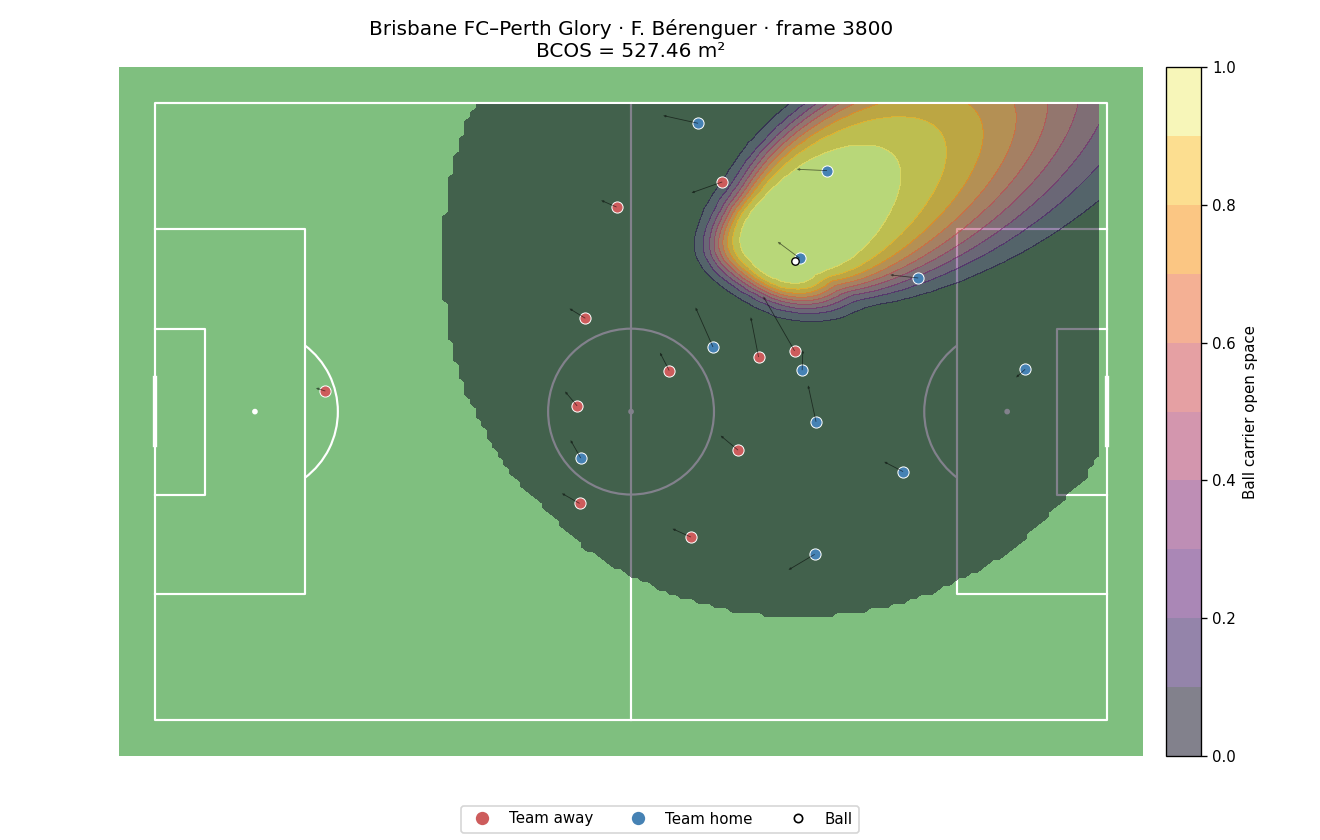

In [5]:
import os
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from PRESS import PRESS
from PRESS.extras import BCOS
from PRESS.visualization import plot_bcos

summary = json.loads((root / "data/examples/bcos/example_summary.json").read_text())
default_dir = root.parent / "opendata/data/processed/2026-10-15_training_v5_outfield/matches/1925299"
match_dir = Path(os.environ.get("PRESS_BCOS_MATCH_DIR", str(default_dir)))
frame_id = summary["frame_id"]
if (match_dir / "1925299_tracking.parquet").is_file():
    press = PRESS.from_skillcorner(match_dir)
    bcos = BCOS(press.tracking_data)
    result = bcos.compute_bcos(frame_id)
    assert np.isclose(result["BCOS area"], summary["bcos_area_m2"], rtol=0, atol=1e-6)
    plot_bcos(bcos, frame_id, figsize=(11, 7), title_fontsize=12, legend_fontsize=9)
    plt.gcf().axes[0].set_title(
        "Brisbane FC–Perth Glory · F. Bérenguer · frame 3800\n"
        f"BCOS = {result['BCOS area']:.2f} m²", fontsize=12)
else:
    # Saved output of the same observed-frame calculation.
    from IPython.display import Image, display
    display(Image(filename=str(root / "figures/vignette_10_bcos.png")))
plt.show()


## Spatiotemporal statistics for one match

BCOS is also a descriptive statistic of a match. Using the same Brisbane FC–Perth Glory game as above, we report how the BCOS area varies across the pitch, with the position of the carrier, and over the course of the match. The values are the BCOS areas computed at the action-choice checkpoints of the match: the canonical outfield, no-shot decision states, each with its original production value. The sample contains 1,928 checkpoints from 931 individual possessions, 1,238 checkpoints from 592 possessions for Brisbane and 690 from 339 for Perth.

### Spatial distribution by carrier position

The two teams are oriented to attack right, including after halftime. BCOS itself is computed on a one-metre destination grid, and the spatial map uses the 10 × 6 grid of xT for display. For team $a$ and carrier-origin cell $g$, the colour is the mean BCOS area of the checkpoints whose carrier occupies that cell,

$$
\bar A_{a,g}=\frac{1}{n_{a,g}}\sum_{j:\,a_j=a,\,r_{B,j}\in g}A_{\mathrm{BCOS}}(s_j).
$$

Both teams share one colour scale, and the labels give the number of distinct individual possessions in each cell.

![Mean BCOS by carrier-origin cell, on the same 10 × 6 grid as xT. Labels count distinct individual possessions.](../../../figures/bcos_match_spatial.png)

Brisbane's mean BCOS is 548.31 m² at defensive-third checkpoints and 365.72 m² in the central third, compared with 277.33 and 260.13 m² for Perth. In the attacking third the means are 81.64 and 68.23 m², respectively. Brisbane therefore has more accessible area in its defensive and central states, and the gap is smaller in the attacking third. A simple reading of the difference in the defensive third is that Perth applies less pressure on Brisbane's build-up than Brisbane applies on Perth's, which leaves Brisbane's carriers more open space.

### Temporal variation

A further use of BCOS is to study its temporal trend and draw information on how the match evolves, separately for each team and carrier-origin third.

![Observed BCOS checkpoints and centred five-minute means, split by carrier-origin third and half.](../../../figures/bcos_match_temporal.png)

In the defensive third, Brisbane's mean rises from 493.02 m² in the first half to 592.92 m² in the second, whereas Perth's falls from 312.02 to 212.03 m². The difference between the teams therefore widens as the match goes on. In the central third Brisbane stays at a similar level (359.05 → 370.48 m²) while Perth decreases (291.39 → 212.47 m²). In the attacking third, the means change less for both teams. [Half/third summaries](../../../data/examples/bcos/period_third_summary.csv).

Overall, Brisbane has more space than Perth to build from the back in both halves, and the advantage grows in the second half. A simple reading is that Perth applies less pressure on Brisbane's build-up and also undergoes more pressure on its own, since its carriers have less space in the defensive third, especially after the break. The number of individual possessions (592 for Brisbane and 339 for Perth) and of checkpoints (1,238 and 690) points in the same direction: Brisbane has more of the ball and Perth defends in a more closed shape. These are indications of how the match developed.


## Scope and references

BCOS assumes straight hypothetical routes, effective movement limits, logistic arrival uncertainty and an additive competing-hazard approximation across defenders and route locations, with arrival uncertainty and carrier position modeled separately. Body posture, ball-control skill, adaptive defensive reactions and realized route choice are outside the model, and the match-level summaries refer to the sampled action-choice checkpoints.

Concept and regional temporal analysis: Bandara et al. [@bandara2025bcos]. Arrival/control framework: Spearman [@spearman2017; @spearman2018beyond]. Movement-scale context: Bradley et al. [@bradley2009running] define the speed categories used as operational references (jogging from about 2 m/s, high-speed running from 5.5 m/s, sprinting around 7 m/s); Carling [@carling2010ballrunning] reports speeds when running with the ball, with a mean peak of 24.7 km/h (about 6.86 m/s); Benhassen et al. [@benhassen2026dribbling] report reduced sprint capacity when dribbling. Tracking: [@skillcorner-opendata]. The spatial interception construction and its numerical implementation are PRESS-specific derivations.

[Spatial support](../../../data/examples/bcos/grid_support.csv) · [spatial statistics](../../../data/examples/bcos/spatial_cells.csv) · [temporal statistics](../../../data/examples/bcos/temporal_thirds.csv).